In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv("train_cl.csv")
target = "Item_Outlet_Sales"
print(train.shape)
train.head()

(8523, 12)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.022911,Fruits and Vegetables,182.0950,OUT010,1998,Small,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.016164,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


=== Target Skewness ===
Original: 1.1775
Log1p:    -0.8823


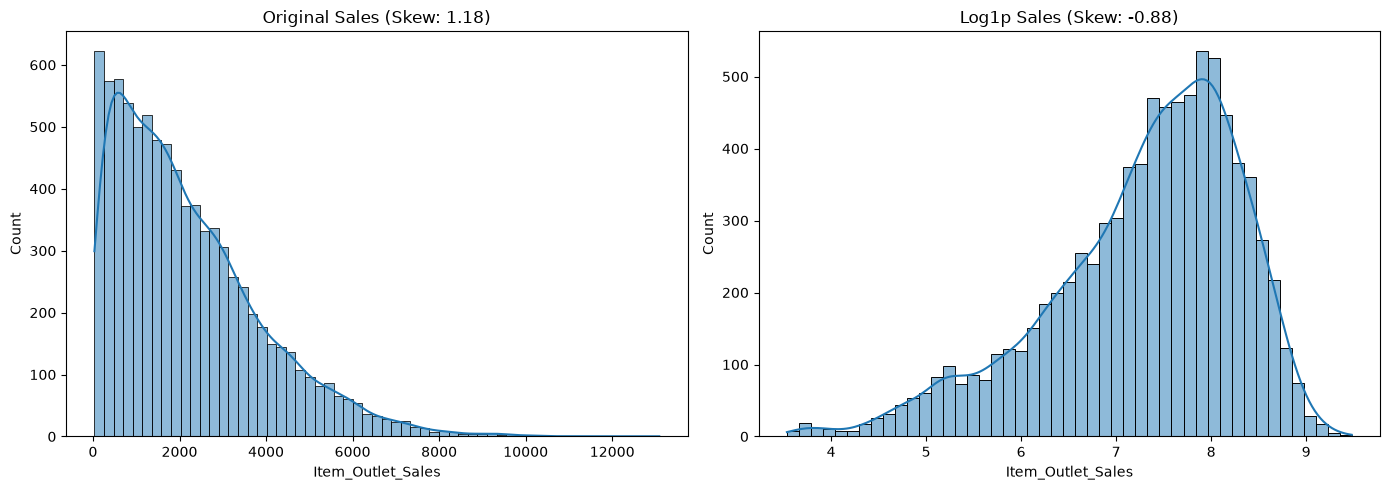

In [2]:
skew_orig = train[target].skew()
skew_log = np.log1p(train[target]).skew()

print("=== Target Skewness ===")
print(f"Original: {skew_orig:.4f}")
print(f"Log1p:    {skew_log:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train[target], kde=True, ax=axes[0])
axes[0].set_title(f"Original Sales (Skew: {skew_orig:.2f})")

sns.histplot(np.log1p(train[target]), kde=True, ax=axes[1])
axes[1].set_title(f"Log1p Sales (Skew: {skew_log:.2f})")

plt.tight_layout()
plt.show()

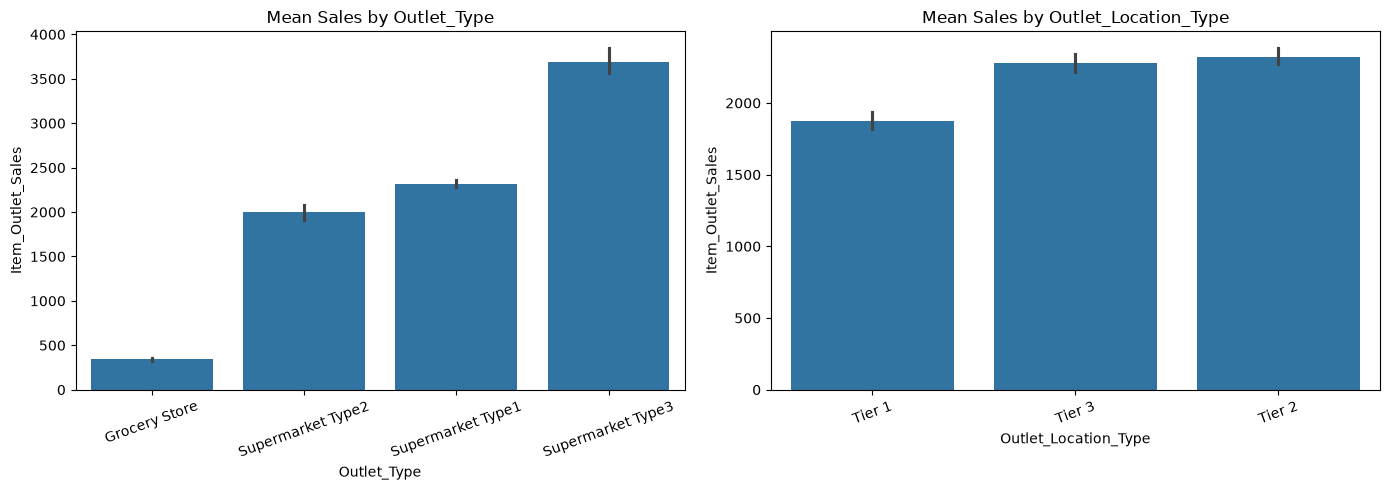

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, ["Outlet_Type", "Outlet_Location_Type"]):
    order = train.groupby(col)[target].mean().sort_values().index
    sns.barplot(data=train, x=col, y=target, order=order, ax=ax)
    ax.set_title(f"Mean Sales by {col}")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

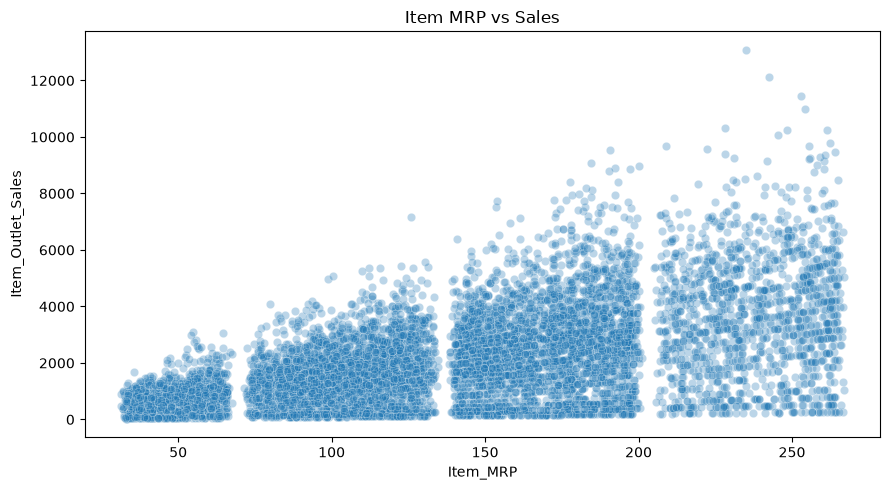

In [4]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=train, x="Item_MRP", y=target, alpha=0.3)
plt.title("Item MRP vs Sales")
plt.tight_layout()
plt.show()

In [5]:
train["Item_Cat"] = train["Item_Identifier"].str[:2]

print("=== Item Category Counts ===")
print(train["Item_Cat"].value_counts())

print("\n=== Fat Content in NC Items ===")
print(train.loc[train["Item_Cat"] == "NC", "Item_Fat_Content"].value_counts())

=== Item Category Counts ===
Item_Cat
FD    6125
NC    1599
DR     799
Name: count, dtype: int64

=== Fat Content in NC Items ===
Item_Fat_Content
Low Fat    1599
Name: count, dtype: int64


In [6]:
numeric_cols = [
    "Item_Weight",
    "Item_Visibility",
    "Item_MRP",
    "Outlet_Establishment_Year"
]

corrs = train[numeric_cols].corrwith(train[target])

print("=== Correlations with Sales ===")
print(corrs.sort_values(ascending=False))

=== Correlations with Sales ===
Item_MRP                     0.567574
Item_Weight                  0.013162
Outlet_Establishment_Year   -0.049135
Item_Visibility             -0.126026
dtype: float64


In [7]:
outlet_sales = train.groupby(
    ["Outlet_Identifier", "Outlet_Type",
     "Outlet_Establishment_Year", "Outlet_Size"]
)[target].agg(["count", "mean", "std"]).reset_index()

print("=== Sales Statistics by Outlet ===")
print(outlet_sales.to_string(index=False))

=== Sales Statistics by Outlet ===
Outlet_Identifier       Outlet_Type  Outlet_Establishment_Year Outlet_Size  count        mean         std
           OUT010     Grocery Store                       1998       Small    555  339.351662  271.014855
           OUT013 Supermarket Type1                       1987        High    932 2298.995256 1533.531664
           OUT017 Supermarket Type1                       2007       Small    926 2340.675263 1550.778025
           OUT018 Supermarket Type2                       2009      Medium    928 1995.498739 1375.932889
           OUT019     Grocery Store                       1985       Small    528  340.329723  249.979449
           OUT027 Supermarket Type3                       1985      Medium    935 3694.038558 2127.760054
           OUT035 Supermarket Type1                       2004       Small    930 2438.841866 1538.512533
           OUT045 Supermarket Type1                       2002       Small    929 2192.384798 1462.399658
           

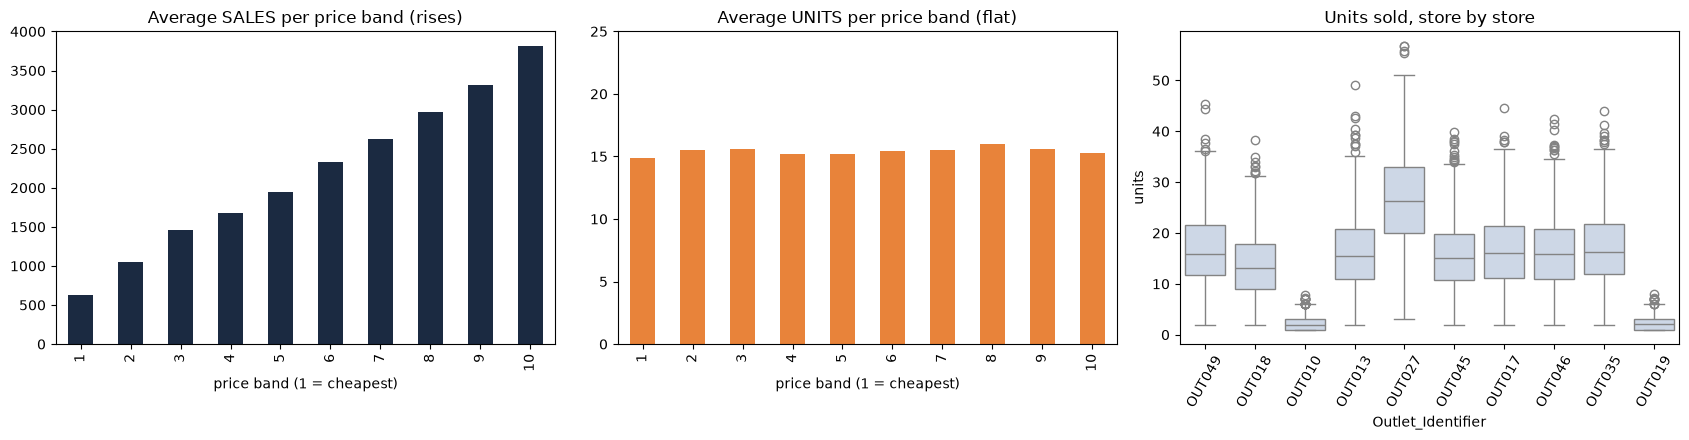

In [8]:
train["units"] = train["Item_Outlet_Sales"] / train["Item_MRP"]
price_band = pd.qcut(train["Item_MRP"], 10, labels=range(1, 11))   # 10 equal-sized price bands, 1 = cheapest

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

train.groupby(price_band, observed=True)[target].mean().plot(kind="bar", ax=axes[0], color="#1B2A41")
axes[0].set_title("Average SALES per price band (rises)")
axes[0].set_xlabel("price band (1 = cheapest)")

train.groupby(price_band, observed=True)["units"].mean().plot(kind="bar", ax=axes[1], color="#E8833A")
axes[1].set_title("Average UNITS per price band (flat)")
axes[1].set_xlabel("price band (1 = cheapest)")
axes[1].set_ylim(0, 25)

sns.boxplot(data=train, x="Outlet_Identifier", y="units", ax=axes[2], color="#C9D6EA")
axes[2].set_title("Units sold, store by store")
axes[2].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

Rows whose units are within 0.02 of a whole number: 17.6%   (pure chance would give about 4%)


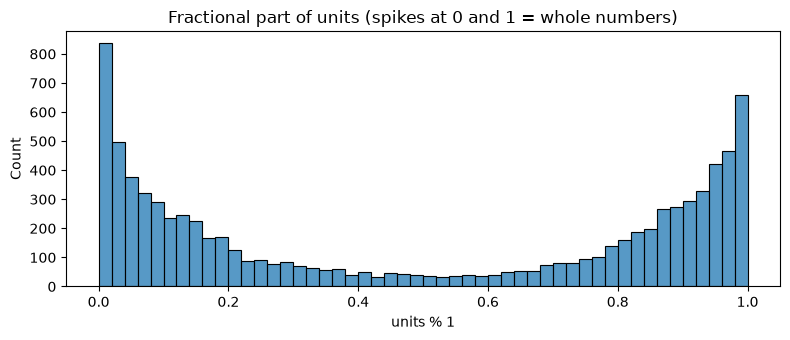

In [9]:
fraction = train["units"] % 1
close_to_whole = (np.minimum(fraction, 1 - fraction) < 0.02).mean()
print(f"Rows whose units are within 0.02 of a whole number: {close_to_whole:.1%}   (pure chance would give about 4%)")

plt.figure(figsize=(8, 3.5))
sns.histplot(fraction, bins=50)
plt.title("Fractional part of units (spikes at 0 and 1 = whole numbers)")
plt.xlabel("units % 1")
plt.tight_layout()
plt.show()

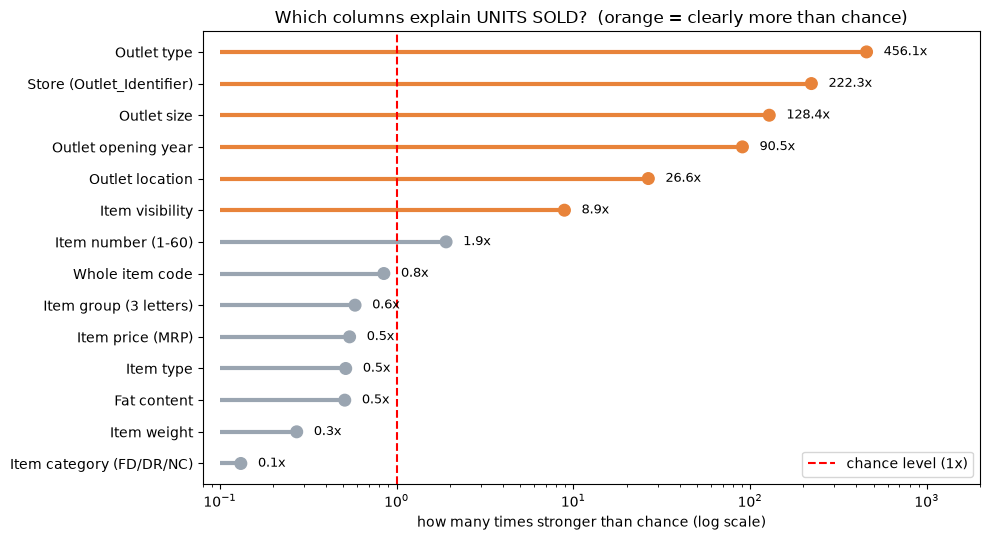

,column,share_explained,chance_level,times_stronger_than_chance
0,Outlet type,0.4267,0.0009,456.1195
1,Store (Outlet_Identifier),0.4284,0.0019,222.2788
2,Outlet size,0.0841,0.0007,128.4038
3,Outlet opening year,0.1548,0.0017,90.5068
4,Outlet location,0.0206,0.0008,26.5686
5,Item visibility,0.0193,0.0022,8.9050
6,Item number (1-60),0.0170,0.0089,1.9057
7,Whole item code,0.1626,0.1919,0.8470
8,Item group (3 letters),0.0062,0.0107,0.5821
9,Item price (MRP),0.0010,0.0019,0.5421


In [10]:
train["item_number"] = train["Item_Identifier"].str[3:].astype(int)   # the 15 in FDA15
train["item_category"] = train["Item_Identifier"].str[:2]               # FD / DR / NC
train["item_group"] = train["Item_Identifier"].str[:3]                  # FDA, DRC, NCL ...

candidates = {
    "Store (Outlet_Identifier)": "Outlet_Identifier",
    "Outlet type": "Outlet_Type",
    "Outlet size": "Outlet_Size",
    "Outlet location": "Outlet_Location_Type",
    "Outlet opening year": "Outlet_Establishment_Year",
    "Item price (MRP)": "Item_MRP",
    "Item weight": "Item_Weight",
    "Item visibility": "Item_Visibility",
    "Fat content": "Item_Fat_Content",
    "Item type": "Item_Type",
    "Item category (FD/DR/NC)": "item_category",
    "Item group (3 letters)": "item_group",
    "Item number (1-60)": "item_number",
    "Whole item code": "Item_Identifier",
}


def share_explained(groups, values):
    """Share of the variation in `values` explained by which group a row is in (0 = nothing, 1 = everything)."""
    codes = pd.factorize(groups)[0]
    count = np.bincount(codes)
    total = np.bincount(codes, weights=values)
    return np.sum(count * (total / count - values.mean()) ** 2) / np.sum((values - values.mean()) ** 2)


def relevance(target_column, n_shuffles=200):
    rng = np.random.default_rng(0)
    values = train[target_column].values
    rows = []
    for label, column in candidates.items():
        groups = train[column]
        if groups.dtype.kind == "f":                      # decimal columns: cut into 10 equal-sized bands
            groups = pd.qcut(groups, 10, duplicates="drop")
        observed = share_explained(groups, values)
        by_chance = [share_explained(groups, rng.permutation(values)) for _ in range(n_shuffles)]
        rows.append([label, observed, np.percentile(by_chance, 95)])
    result = pd.DataFrame(rows, columns=["column", "share_explained", "chance_level"])
    result["times_stronger_than_chance"] = result["share_explained"] / result["chance_level"]
    return result.sort_values("times_stronger_than_chance", ascending=False).reset_index(drop=True)


def plot_relevance(result, title):
    result = result.iloc[::-1].reset_index(drop=True)
    shown = result["times_stronger_than_chance"].clip(lower=0.1)          # keep zeros visible on the log axis
    colors = ["#E8833A" if t > 2 else "#9AA5B1" for t in result["times_stronger_than_chance"]]
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.hlines(range(len(result)), 0.1, shown, colors=colors, linewidth=3)
    ax.scatter(shown, range(len(result)), c=colors, s=70, zorder=3)
    for i, t in enumerate(result["times_stronger_than_chance"]):
        ax.text(max(t, 0.1) * 1.25, i, f"{t:.1f}x", va="center", fontsize=9)
    ax.axvline(1, color="red", linestyle="--", label="chance level (1x)")
    ax.set_yticks(range(len(result)))
    ax.set_yticklabels(result["column"])
    ax.set_xscale("log")
    ax.set_xlim(0.08, 2000)
    ax.set_xlabel("how many times stronger than chance (log scale)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


units_result = relevance("units")
plot_relevance(units_result, "Which columns explain UNITS SOLD?  (orange = clearly more than chance)")
units_result.round(4)

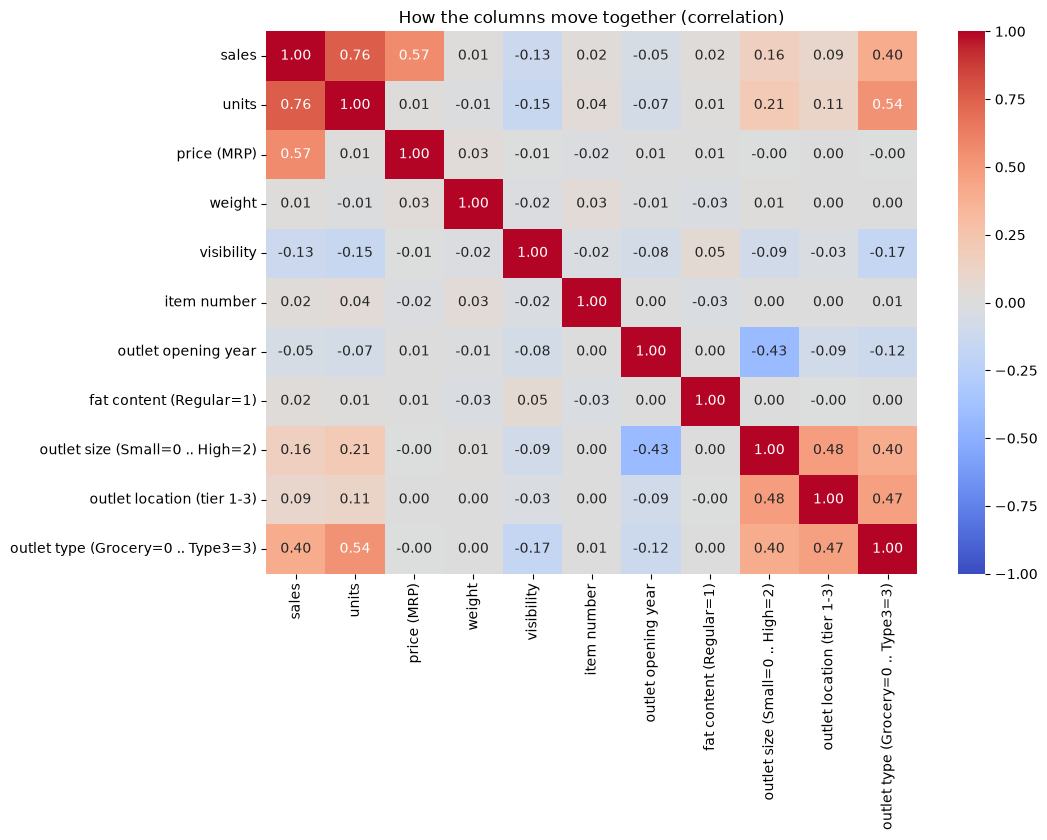

In [11]:
numbers = pd.DataFrame({
    "sales": train[target],
    "units": train["units"],
    "price (MRP)": train["Item_MRP"],
    "weight": train["Item_Weight"],
    "visibility": train["Item_Visibility"],
    "item number": train["item_number"],
    "outlet opening year": train["Outlet_Establishment_Year"],
    "fat content (Regular=1)": (train["Item_Fat_Content"] == "Regular").astype(int),
    "outlet size (Small=0 .. High=2)": train["Outlet_Size"].map({"Small": 0, "Medium": 1, "High": 2}),
    "outlet location (tier 1-3)": train["Outlet_Location_Type"].str[-1].astype(int),
    "outlet type (Grocery=0 .. Type3=3)": train["Outlet_Type"].map({"Grocery Store": 0, "Supermarket Type1": 1, "Supermarket Type2": 2, "Supermarket Type3": 3}),
})

plt.figure(figsize=(11, 8.5))
sns.heatmap(numbers.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("How the columns move together (correlation)")
plt.tight_layout()
plt.show()

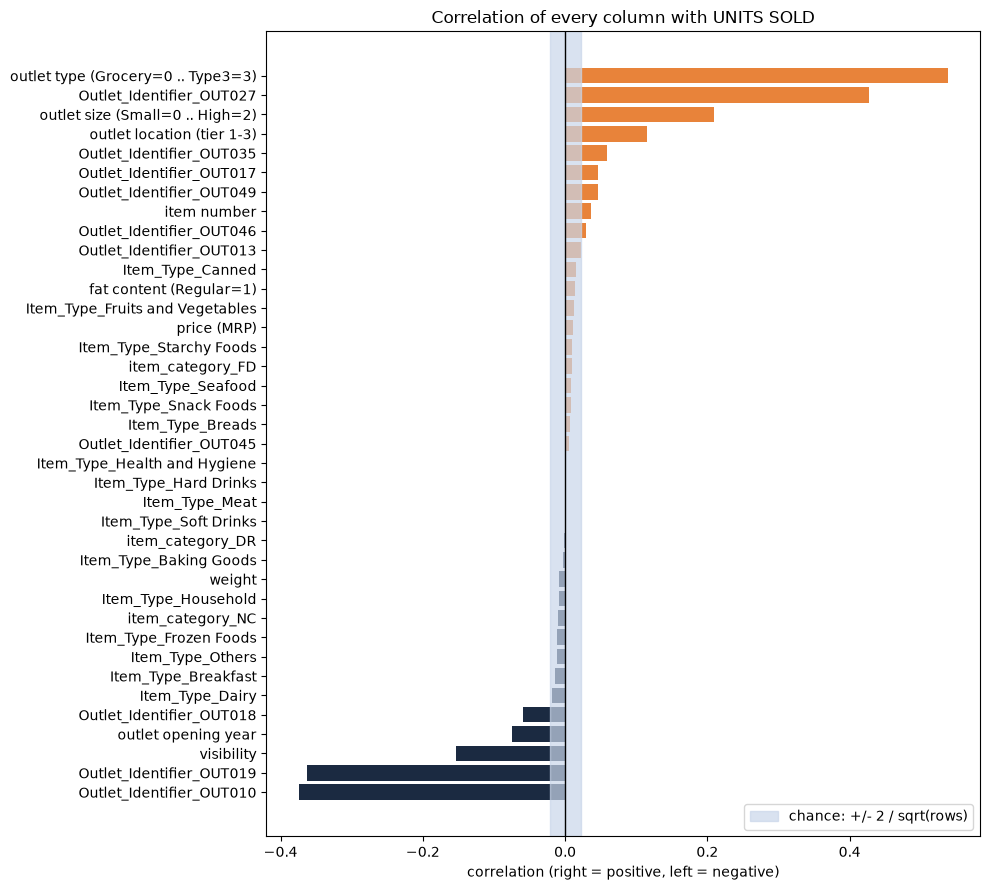

Largest links:
outlet type (Grocery=0 .. Type3=3)    0.538
Outlet_Identifier_OUT027              0.427
Outlet_Identifier_OUT010             -0.374
Outlet_Identifier_OUT019             -0.363
outlet size (Small=0 .. High=2)       0.209


In [12]:
text_columns = ["Outlet_Identifier", "Item_Type", "item_category"]        # no natural order: one 0/1 column per value
features = pd.concat([numbers.drop(columns=["sales", "units"]), pd.get_dummies(train[text_columns]).astype(int)], axis=1)
noise = 2 / np.sqrt(len(train))                                              # correlations inside +/- noise are just chance


def plot_correlations(values, title):
    r = features.corrwith(values).sort_values()
    plt.figure(figsize=(10, 9))
    plt.barh(r.index, r.values, color=["#E8833A" if v > 0 else "#1B2A41" for v in r.values])
    plt.axvspan(-noise, noise, color="#C9D6EA", alpha=0.7, label="chance: +/- 2 / sqrt(rows)")
    plt.axvline(0, color="black", linewidth=1)
    plt.xlabel("correlation (right = positive, left = negative)")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()
    print("Largest links:")
    print(r[r.abs().sort_values(ascending=False).index[:5]].round(3).to_string())


plot_correlations(train["units"], "Correlation of every column with UNITS SOLD")

Average item visibility by store type:
Outlet_Type
Grocery Store        0.1081
Supermarket Type1    0.0655
Supermarket Type2    0.0663
Supermarket Type3    0.0634
Name: Item_Visibility, dtype: float64


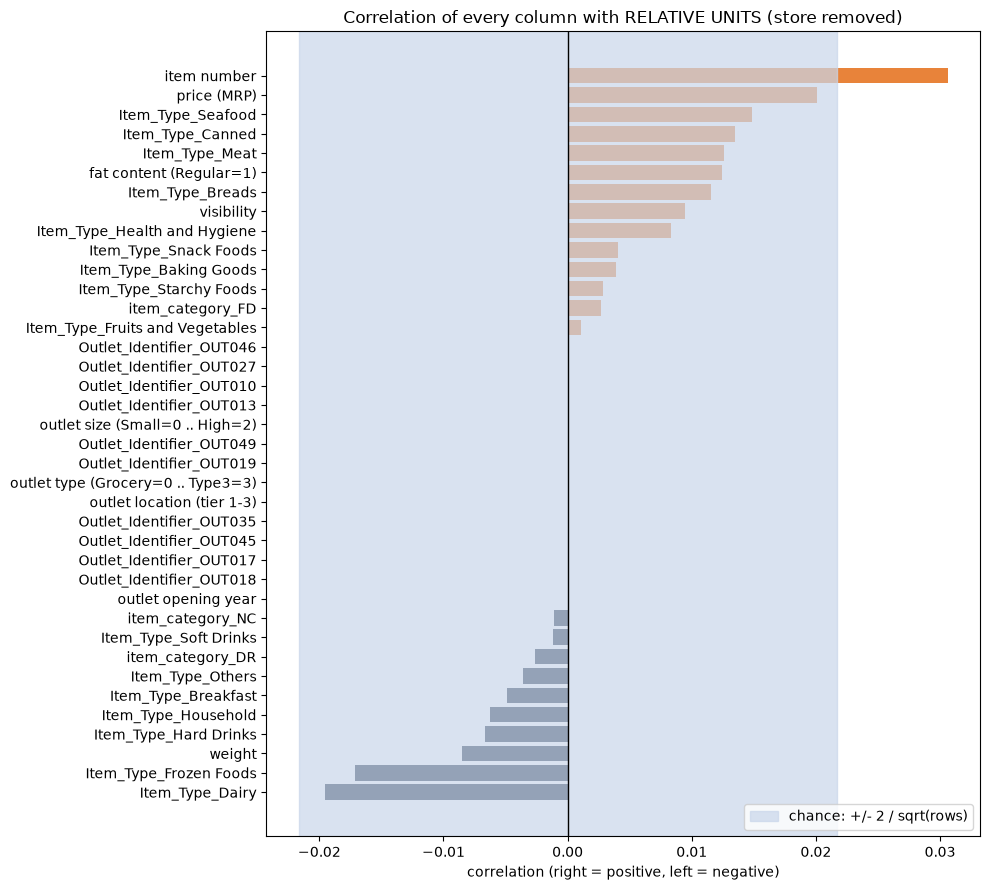

Largest links:
item number               0.031
price (MRP)               0.020
Item_Type_Dairy          -0.020
Item_Type_Frozen Foods   -0.017
Item_Type_Seafood         0.015


In [13]:
train["relative_units"] = train["units"] / train.groupby("Outlet_Identifier")["units"].transform("mean")

print("Average item visibility by store type:")
print(train.groupby("Outlet_Type")["Item_Visibility"].mean().round(4))

plot_correlations(train["relative_units"], "Correlation of every column with RELATIVE UNITS (store removed)")

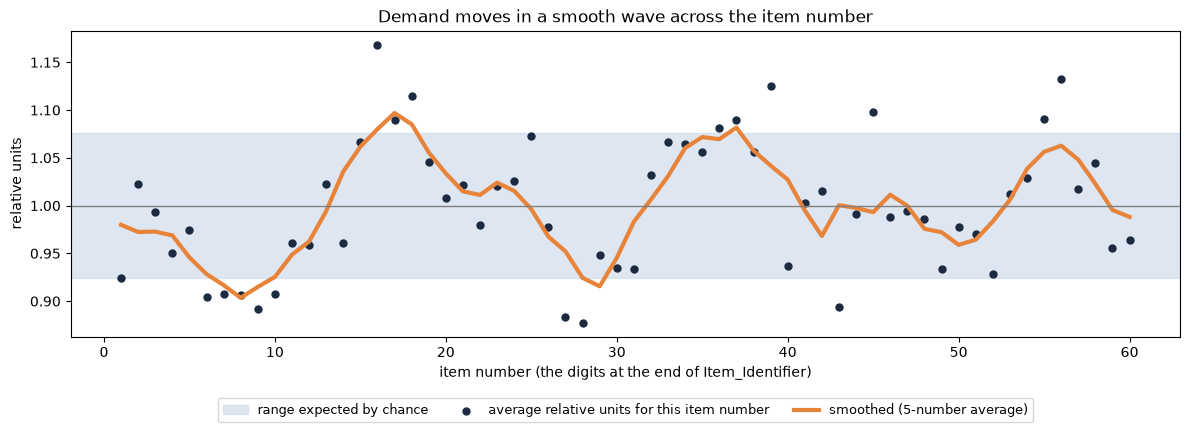

17 of the 60 item numbers fall outside the chance range (pure luck would give about 3)
Does the wave appear in both food and drinks? Correlation of the two waves: 0.53


In [14]:
by_number = train.groupby("item_number")["relative_units"].agg(["mean", "count"])
chance = 2 * train["relative_units"].std() / np.sqrt(by_number["count"].mean())        # how far an average can wander by luck
smooth = by_number["mean"].rolling(5, center=True, min_periods=1).mean()               # 5-number moving average
outside = ((by_number["mean"] - 1).abs() > chance).sum()

plt.figure(figsize=(12, 4.5))
plt.axhspan(1 - chance, 1 + chance, color="#C9D6EA", alpha=0.6, label="range expected by chance")
plt.scatter(by_number.index, by_number["mean"], color="#1B2A41", s=25, label="average relative units for this item number")
plt.plot(smooth.index, smooth, color="#E8833A", linewidth=3, label="smoothed (5-number average)")
plt.axhline(1, color="grey", linewidth=1)
plt.xlabel("item number (the digits at the end of Item_Identifier)")
plt.ylabel("relative units")
plt.title("Demand moves in a smooth wave across the item number")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

print(f"{outside} of the 60 item numbers fall outside the chance range (pure luck would give about 3)")

by_category = train.groupby(["item_category", "item_number"])["relative_units"].mean().unstack(0)
print("Does the wave appear in both food and drinks? Correlation of the two waves:", round(by_category["FD"].corr(by_category["DR"]), 2))

Prediction error of store x price x item-number curve: 1061.9


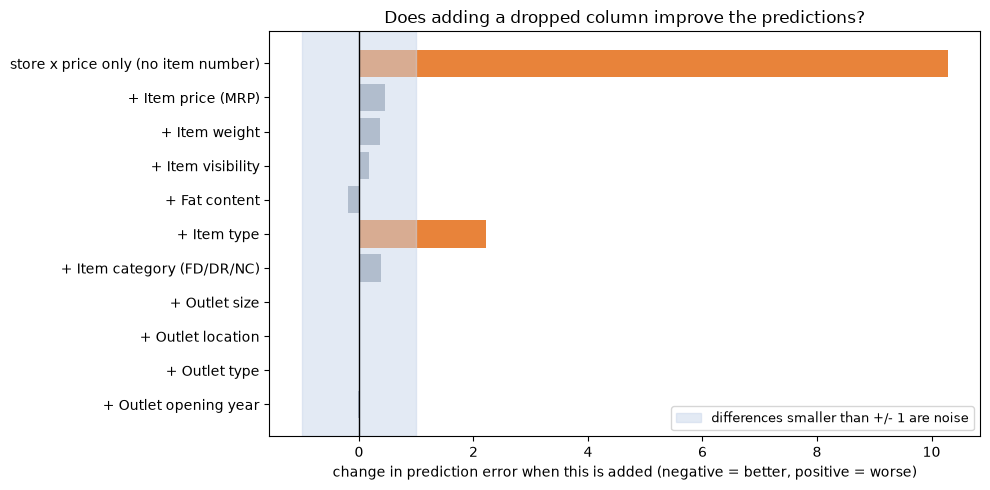

,model,change_in_error
10,+ Outlet opening year,-0.02
9,+ Outlet type,0.01
8,+ Outlet location,-0.00
7,+ Outlet size,0.01
6,+ Item category (FD/DR/NC),0.39
5,+ Item type,2.23
4,+ Fat content,-0.19
3,+ Item visibility,0.17
2,+ Item weight,0.37
1,+ Item price (MRP),0.45


In [15]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.preprocessing import SplineTransformer

curve = SplineTransformer(n_knots=16, degree=3).fit_transform(train[["item_number"]])     # smooth curve of the item number


def cv_rmse(extra_columns=None, use_curve=True, seeds=(0, 1, 2)):
    """Prediction error of: store average x price x Ridge(curve [+ extra columns]). Lower is better."""
    columns = [curve] if use_curve else []
    if extra_columns is not None:
        columns.append(extra_columns)
    X = np.hstack(columns) if columns else np.ones((len(train), 1))
    scores = []
    for seed in seeds:
        prediction = np.zeros(len(train))
        for learn, check in KFold(5, shuffle=True, random_state=seed).split(train):
            store_mean = train.iloc[learn].groupby("Outlet_Identifier")["units"].mean()
            mean_learn = train["Outlet_Identifier"].iloc[learn].map(store_mean).values
            mean_check = train["Outlet_Identifier"].iloc[check].map(store_mean).values
            model = Ridge(alpha=10).fit(X[learn], train["units"].values[learn] / mean_learn)
            prediction[check] = mean_check * model.predict(X[check]) * train["Item_MRP"].values[check]
        scores.append(np.sqrt(np.mean((train[target].values - prediction) ** 2)))
    return np.mean(scores)


def as_numbers(column):
    if not pd.api.types.is_numeric_dtype(train[column]):
        return pd.get_dummies(train[column]).astype(float).values            # text: one 0/1 column per category
    values = train[column].values.astype(float)
    return ((values - values.mean()) / values.std()).reshape(-1, 1)          # numbers: put on a common scale


base = cv_rmse()
rows = [["store x price only (no item number)", cv_rmse(use_curve=False) - base],
        ["+ Item price (MRP)", cv_rmse(as_numbers("Item_MRP")) - base]]
for label, column in [("Item weight", "Item_Weight"), ("Item visibility", "Item_Visibility"), ("Fat content", "Item_Fat_Content"),
                      ("Item type", "Item_Type"), ("Item category (FD/DR/NC)", "item_category"), ("Outlet size", "Outlet_Size"),
                      ("Outlet location", "Outlet_Location_Type"), ("Outlet type", "Outlet_Type"), ("Outlet opening year", "Outlet_Establishment_Year")]:
    rows.append(["+ " + label, cv_rmse(as_numbers(column)) - base])
change = pd.DataFrame(rows, columns=["model", "change_in_error"]).iloc[::-1]

print(f"Prediction error of store x price x item-number curve: {base:.1f}")
plt.figure(figsize=(10, 5))
plt.barh(change["model"], change["change_in_error"], color=["#E8833A" if v > 0.5 else "#9AA5B1" for v in change["change_in_error"]])
plt.axvspan(-1, 1, color="#C9D6EA", alpha=0.5, label="differences smaller than +/- 1 are noise")
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("change in prediction error when this is added (negative = better, positive = worse)")
plt.title("Does adding a dropped column improve the predictions?")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()
change.round(2)

In [16]:
pd.set_option("display.max_colwidth", None)
decision = pd.DataFrame([
    ["Outlet_Identifier (store)", "KEEP", "Sets the level of units sold: explains 43% of the variation in units (Steps 4 and 6)."],
    ["Item_MRP (price)", "KEEP, as the multiplier", "Sales = price x units. It does not predict units (Steps 3 and 5), it only turns units back into sales."],
    ["Item_Identifier, number part only", "KEEP", "The only column with a real signal once the store is removed: a smooth +/-10% wave across the numbers 1 to 60 (Steps 7 and 8)."],
    ["Outlet_Type, Outlet_Size, Outlet_Location_Type, Outlet opening year", "DROP", "Coarser labels of the store. Nothing is left after removing the store (Steps 5 to 7)."],
    ["Item_Visibility", "DROP", "Looked relevant (Steps 4 and 6) only because it differs between store types. At chance after removing the store (Steps 5 to 7)."],
    ["Item_Weight", "DROP", "At chance level (Steps 4, 7, 9) and does not improve predictions (Step 9)."],
    ["Item_Fat_Content, Item_Type, item category and group", "DROP", "At chance level (Steps 7, 9). Item type makes predictions slightly worse (Step 9)."],
    ["Item_Identifier, letters part and whole code", "DROP", "1,559 exact items with about 5 rows each: no more than luck (Steps 4, 7, 9)."],
], columns=["column", "decision", "why (evidence)"])
decision

,column,decision,why (evidence)
0,Outlet_Identifier (store),KEEP,Sets the level of units sold: explains 43% of the variation in units (Steps 4 and 6).
1,Item_MRP (price),"KEEP, as the multiplier","Sales = price x units. It does not predict units (Steps 3 and 5), it only turns units back into sales."
2,"Item_Identifier, number part only",KEEP,The only column with a real signal once the store is removed: a smooth +/-10% wave across the numbers 1 to 60 (Steps 7 and 8).
3,"Outlet_Type, Outlet_Size, Outlet_Location_Type, Outlet opening year",DROP,Coarser labels of the store. Nothing is left after removing the store (Steps 5 to 7).
4,Item_Visibility,DROP,Looked relevant (Steps 4 and 6) only because it differs between store types. At chance after removing the store (Steps 5 to 7).
5,Item_Weight,DROP,"At chance level (Steps 4, 7, 9) and does not improve predictions (Step 9)."
6,"Item_Fat_Content, Item_Type, item category and group",DROP,"At chance level (Steps 7, 9). Item type makes predictions slightly worse (Step 9)."
7,"Item_Identifier, letters part and whole code",DROP,"1,559 exact items with about 5 rows each: no more than luck (Steps 4, 7, 9)."
